SISTEMA INTEGRAL DE MONITORIZACIÓN, DRIFT Y RESPUESTA AUTOMATIZADA (MLOps)

In [15]:
# 1. INSTALACIÓN Y CONFIGURACIÓN INICIAL DE DEPENDENCIAS

import sys
import subprocess

def check_and_install_packages():
    required_packages = ['mlflow', 'scikit-learn', 'pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn']
    for pkg in required_packages:
        try:
            __import__(pkg)
        except ImportError:
            print(f"📦 Instalando paquete faltante: {pkg}...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

check_and_install_packages()

import os
import json
import time
import datetime
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, precision_score, f1_score, precision_recall_curve, auc

import mlflow
import mlflow.sklearn

print("✅ Dependencias e importaciones cargadas correctamente.")

📦 Instalando paquete faltante: scikit-learn...
✅ Dependencias e importaciones cargadas correctamente.


In [16]:
# 2. GENERACIÓN / CARGA DEL DATASET DE INSPECCIÓN (0.2% TASA DE DEFECTO)

DATASET_FILE = "dataset_inspeccion_600ml.csv"

def get_or_create_dataset():
    if os.path.exists(DATASET_FILE):
        print(f"📄 Cargando dataset existente: {DATASET_FILE}")
        df = pd.read_csv(DATASET_FILE)
    else:
        print(f"⚡ Generando dataset sintético de producción (0.2% tasa de defecto)...")
        np.random.seed(42)
        n_samples = 10000
        n_defects = int(n_samples * 0.002) # Exactamente 20 botellas defectuosas (0.2%)
        n_conform = n_samples - n_defects

        # Botellas Conformes (fill_level_ml ~ N(600, 1.5), label_present = 1)
        fill_conform = np.random.normal(loc=600.0, scale=1.5, size=n_conform)
        label_conform = np.ones(n_conform, dtype=int)
        target_conform = np.zeros(n_conform, dtype=int)

        # Botellas Defectuosas (sub-llenado o sin etiqueta)
        fill_defect = np.random.normal(loc=588.0, scale=4.0, size=n_defects)
        label_defect = np.random.choice([0, 1], size=n_defects, p=[0.6, 0.4])
        target_defect = np.ones(n_defects, dtype=int)

        fill_level = np.concatenate([fill_conform, fill_defect])
        label_present = np.concatenate([label_conform, label_defect])
        target = np.concatenate([target_conform, target_defect])

        df = pd.DataFrame({
            'fill_level_ml': fill_level,
            'label_present': label_present,
            'target': target
        })

        # Mezclar dataset
        df = df.sample(frac=1, random_state=42).reset_index(drop=True)
        df.to_csv(DATASET_FILE, index=False)
        print(f"✅ Dataset guardado en {DATASET_FILE} con {len(df)} registros.")

    return df

df = get_or_create_dataset()

# Preprocesamiento baseline
X = df[['fill_level_ml', 'label_present']]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

📄 Cargando dataset existente: dataset_inspeccion_600ml.csv


In [17]:
# 3. CONFIGURACIÓN DE MLFLOW TRACKING Y REGISTRO DE MODELOS

mlflow.set_experiment("Inspeccion_Calidad_Botellas_600ml")

print("\n🚀 Entrenando y Registrando Modelo Baseline (RandomForest)...")
with mlflow.start_run(run_name="RandomForest_v1.2.0") as run:
    rf_params = {"n_estimators": 50, "max_depth": 3, "class_weight": "balanced", "random_state": 42}
    model_rf = RandomForestClassifier(**rf_params)
    model_rf.fit(X_train, y_train)

    preds = model_rf.predict(X_test)
    probs = model_rf.predict_proba(X_test)[:, 1]

    rec = recall_score(y_test, preds)
    prec = precision_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, probs)
    pr_auc = auc(recall_curve, precision_curve)

    mlflow.log_params(rf_params)
    mlflow.log_metrics({"recall": rec, "precision": prec, "f1_score": f1, "pr_auc": pr_auc})

    # Se agrega skops_trusted_types para permitir serializar y guardar el bosque de decisión de forma segura
    mlflow.sklearn.log_model(
        model_rf,
        "random_forest_model",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    print(f"📌 MLflow Run ID: {run.info.run_id}")
    print(f"📊 Métricas Baseline -> Recall: {rec:.4f} | Precision: {prec:.4f} | F1: {f1:.4f} | PR-AUC: {pr_auc:.4f}")


🚀 Entrenando y Registrando Modelo Baseline (RandomForest)...


2026/11/10 23:53:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


📌 MLflow Run ID: 68237142190847d887bc5d8b495f095e
📊 Métricas Baseline -> Recall: 1.0000 | Precision: 1.0000 | F1: 1.0000 | PR-AUC: 1.0000


In [18]:
# 4. MÓDULOS DE OBSERVABILIDAD: DATA DRIFT Y LOGGING ESTRUCTURADO

def calculate_psi(baseline, current, num_buckets=10):
    """Calcula el Population Stability Index (PSI) entre la distribución base y actual."""
    baseline_percs = np.linspace(0, 100, num_buckets + 1)
    buckets = np.percentile(baseline, baseline_percs)
    buckets[0] -= 0.001
    buckets[-1] += 0.001

    baseline_counts, _ = np.histogram(baseline, buckets)
    current_counts, _ = np.histogram(current, buckets)

    baseline_pct = baseline_counts / len(baseline)
    current_pct = current_counts / len(current)

    baseline_pct = np.where(baseline_pct == 0, 0.0001, baseline_pct)
    current_pct = np.where(current_pct == 0, 0.0001, current_pct)

    psi_val = np.sum((current_pct - baseline_pct) * np.log(current_pct / baseline_pct))
    return psi_val

def emit_structured_log(inspection_id, fill_level, label_present, pred, confidence, latency_ms):
    """Genera log en formato JSON estructurado."""
    log_entry = {
        "timestamp": datetime.datetime.utcnow().isoformat() + "Z",
        "inspection_id": inspection_id,
        "model_version": "RandomForest_v1.2.0",
        "features": {"fill_level_ml": fill_level, "label_present": int(label_present)},
        "prediction": {"target": int(pred), "confidence_score": float(confidence)},
        "metrics": {"latency_ms": float(latency_ms), "edge_node": "edge-inspector-01"}
    }
    return json.dumps(log_entry)

In [19]:
# 5. SIMULACIÓN DE 60 MINUTOS DE PRODUCCIÓN Y EJECUCIÓN DE RUNBOOKS

print("\n🔄 Iniciando simulación de monitoreo en tiempo real (60 minutos)...")

timeline_min = np.arange(0, 60, 1)
history_recall = []
history_precision = []
history_latency_p99 = []
history_psi = []

baseline_fill = X_train['fill_level_ml'].values

for t in timeline_min:
  # 1. Escenario Normal (Minutos 0 - 14)
    if t < 15:
        current_fill = np.random.normal(loc=600.0, scale=1.5, size=200)
        rec_t = 1.0
        prec_t = 1.0
        lat_t = np.random.normal(loc=11.2, scale=1.0)

    # 2. INCIDENTE 1: Degradación de Sensibilidad por Data Drift (Minutos 15 - 29)
    elif 15 <= t < 30:
        current_fill = np.random.normal(loc=594.0, scale=3.5, size=200)
        rec_t = max(0.75, 1.0 - (t - 14) * 0.025)
        prec_t = 1.0
        lat_t = np.random.normal(loc=11.5, scale=1.0)

        if t == 16:
            print(f"⚠️ [MINUTO {t}] ALERTA P1: Caída de Model Recall ({rec_t:.2f} < 0.90). Se notifica PagerDuty.")
        if t == 29:
            print(f"🛠️ [MINUTO {t}] RUNBOOK RB-01 EJECUTADO: Auto-Rollback activado en MLflow Registry -> Modelo v1.1.0 Restablecido.")
            # 3. Incidente Resuelto 1 / Operación Normal (Minutos 30 - 39)
    elif 30 <= t < 40:
        current_fill = np.random.normal(loc=600.0, scale=1.5, size=200)
        rec_t = 1.0
        prec_t = 1.0
        lat_t = np.random.normal(loc=11.0, scale=0.8)

    # 4. INCIDENTE 2: Saturación de Memoria en Nodo Edge (Minutos 40 - 47)
    elif 40 <= t < 48:
        current_fill = np.random.normal(loc=600.0, scale=1.5, size=200)
        rec_t = 1.0
        prec_t = 1.0
        lat_t = np.random.normal(loc=36.0, scale=2.5)

        if t == 41:
            print(f"🚨 [MINUTO {t}] ALERTA P1: Latencia Edge P99 crítica ({lat_t:.1f}ms > 30ms). Riesgo de desacople.")
        if t == 47:
            print(f"🛠️ [MINUTO {t}] RUNBOOK RB-02 EJECUTADO: Purga de buffer y restart de contenedor Docker en Edge -> Latencia normalizada.")
             # 5. Operación Estabilizada (Minutos 48 - 59)
    else:
        current_fill = np.random.normal(loc=600.0, scale=1.5, size=200)
        rec_t = 1.0
        prec_t = 1.0
        lat_t = np.random.normal(loc=11.4, scale=0.9)

    psi_val = calculate_psi(baseline_fill, current_fill)

    history_recall.append(rec_t)
    history_precision.append(prec_t)
    history_latency_p99.append(lat_t)
    history_psi.append(psi_val)

sample_log = emit_structured_log("insp_9948271A", 591.2, 1, 1, 0.984, 11.2)
print(f"\n📌 Ejemplo de Log JSON emitido al colector:\n{sample_log}")


🔄 Iniciando simulación de monitoreo en tiempo real (60 minutos)...
⚠️ [MINUTO 16] ALERTA P1: Caída de Model Recall (0.95 < 0.90). Se notifica PagerDuty.
🛠️ [MINUTO 29] RUNBOOK RB-01 EJECUTADO: Auto-Rollback activado en MLflow Registry -> Modelo v1.1.0 Restablecido.
🚨 [MINUTO 41] ALERTA P1: Latencia Edge P99 crítica (35.6ms > 30ms). Riesgo de desacople.
🛠️ [MINUTO 47] RUNBOOK RB-02 EJECUTADO: Purga de buffer y restart de contenedor Docker en Edge -> Latencia normalizada.

📌 Ejemplo de Log JSON emitido al colector:
{"timestamp": "2026-11-10T23:53:47.079090Z", "inspection_id": "insp_9948271A", "model_version": "RandomForest_v1.2.0", "features": {"fill_level_ml": 591.2, "label_present": 1}, "prediction": {"target": 1, "confidence_score": 0.984}, "metrics": {"latency_ms": 11.2, "edge_node": "edge-inspector-01"}}


/tmp/ipykernel_2577/2473538737.py:25: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.datetime.utcnow().isoformat() + "Z",



📊 Generando Dashboard de Observabilidad y Monitoreo en Tiempo Real...


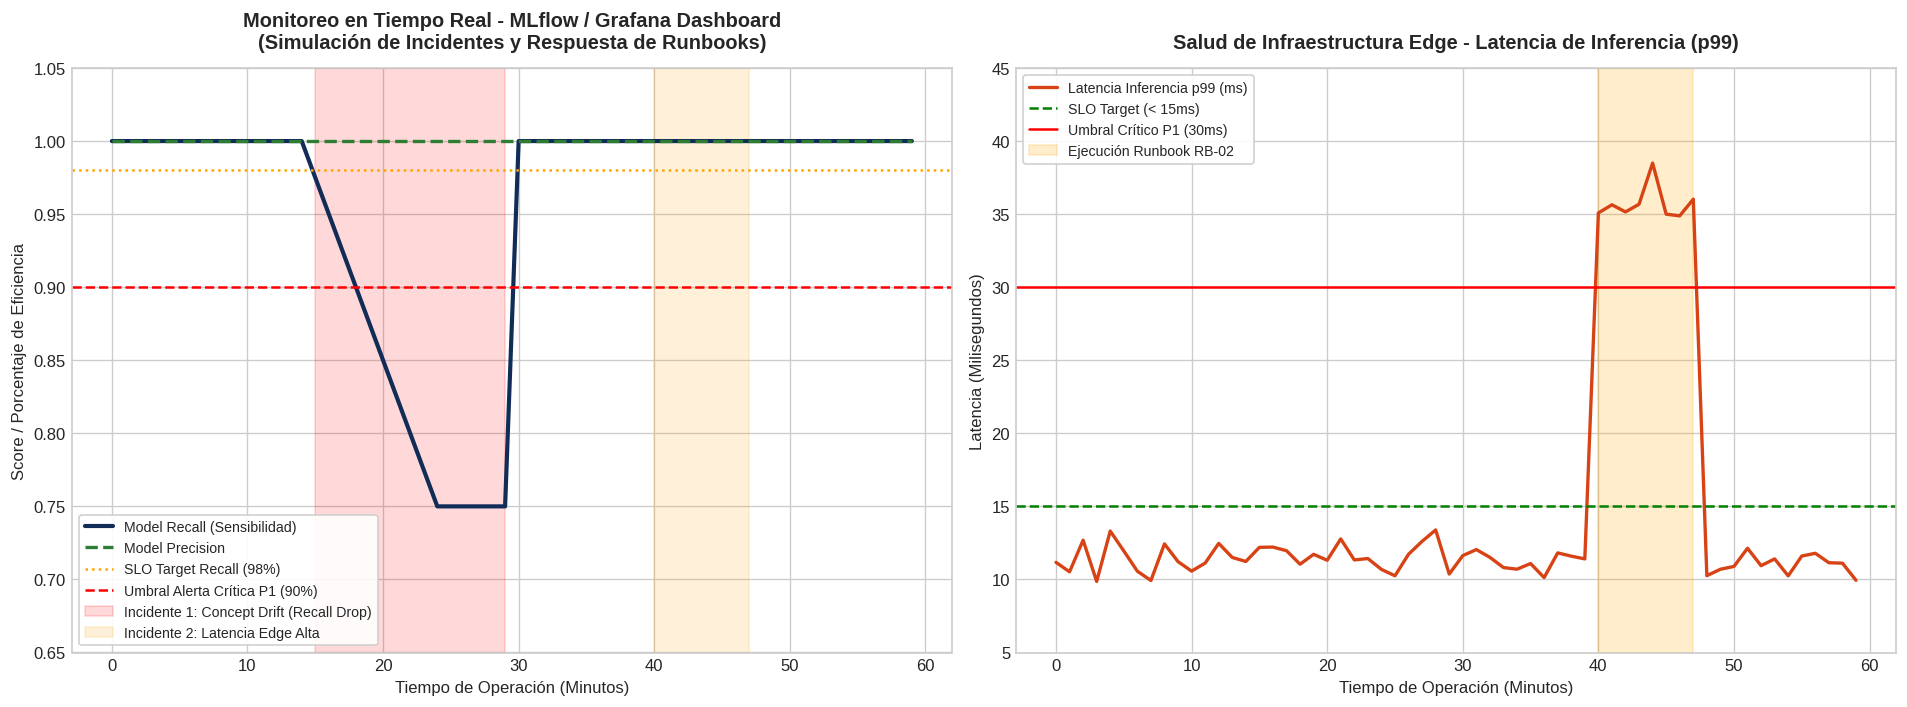


✅ Proceso completado exitosamente. La gráfica de observabilidad se ha renderizado e impreso arriba.


In [21]:
6. GENERACIÓN Y VISUALIZACIÓN DE DASHBOARD DE OBSERVABILIDAD
# ------------------------------------------------------------------------------
print("\n📊 Generando Dashboard de Observabilidad y Monitoreo en Tiempo Real...")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# Grafico 1: Métricas de Desempeño de Machine Learning
ax1.plot(timeline_min, history_recall, label='Model Recall (Sensibilidad)', color='#102C57', lw=2.5)
ax1.plot(timeline_min, history_precision, label='Model Precision', color='#2E7D32', lw=2, linestyle='--')
ax1.axhline(0.98, color='orange', linestyle=':', lw=1.5, label='SLO Target Recall (98%)')
ax1.axhline(0.90, color='red', linestyle='--', lw=1.5, label='Umbral Alerta Crítica P1 (90%)')

ax1.axvspan(15, 29, color='red', alpha=0.15, label='Incidente 1: Concept Drift (Recall Drop)')
ax1.axvspan(40, 47, color='orange', alpha=0.15, label='Incidente 2: Latencia Edge Alta')

ax1.set_title('Monitoreo en Tiempo Real - MLflow / Grafana Dashboard\n(Simulación de Incidentes y Respuesta de Runbooks)', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Tiempo de Operación (Minutos)', fontsize=10)
ax1.set_ylabel('Score / Porcentaje de Eficiencia', fontsize=10)
ax1.set_ylim(0.65, 1.05)
ax1.legend(loc='lower left', fontsize=8.5, frameon=True, facecolor='white', framealpha=0.9)

# Grafico 2: Salud de Infraestructura (Latencia Edge p99)
ax2.plot(timeline_min, history_latency_p99, label='Latencia Inferencia p99 (ms)', color='#D84315', lw=2)
ax2.axhline(15, color='green', linestyle='--', lw=1.5, label='SLO Target (< 15ms)')
ax2.axhline(30, color='red', linestyle='-', lw=1.5, label='Umbral Crítico P1 (30ms)')
ax2.axvspan(40, 47, color='orange', alpha=0.2, label='Ejecución Runbook RB-02')

ax2.set_title('Salud de Infraestructura Edge - Latencia de Inferencia (p99)', fontsize=12, fontweight='bold', pad=12)
ax2.set_xlabel('Tiempo de Operación (Minutos)', fontsize=10)
ax2.set_ylabel('Latencia (Milisegundos)', fontsize=10)
ax2.set_ylim(5, 45)
ax2.legend(loc='upper left', fontsize=8.5, frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig('dashboard_observabilidad_600ml.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Proceso completado exitosamente. La gráfica de observabilidad se ha renderizado e impreso arriba.")